# Auto MPG — сравнение четырёх моделей регрессии
**Автор: Kuat Akylbek · Машиналық оқыту**

Заменяем Palmer Penguins на **Auto MPG**. Предсказываем **MPG**, то есть сколько миль автомобиль проезжает на одном галлоне топлива. Больше MPG — лучше топливная экономичность.

Сравниваются **DecisionTreeRegressor, RandomForestRegressor, GradientBoostingRegressor, XGBRegressor**. В предыдущем опыте был классификатор дерева; здесь целевая величина непрерывная, поэтому используются четыре регрессионные модели. Отдельный Gradient Boosting добавлен вместо классификатора, а дерево не дублируется под двумя названиями.

398 автомобилей, 9 исходных столбцов: 7 входных признаков, целевой MPG и название-идентификатор. Шесть пропусков horsepower заполняются медианой только обучающей части, внутри Pipeline и каждого fold. Строки не удаляются. Origin кодируется one-hot. Название автомобиля не подаётся модели.

**Запуск:** Google Colab → File → Upload notebook → Runtime → Run all. Результаты ниже получены реальным выполнением кода.

Источник: [Quinlan, R. (1993). Auto MPG, UCI](https://doi.org/10.24432/C5859H), лицензия CC BY 4.0. Данные преобразованы в CSV с сохранением всех398 строк.

## 1. Данные и честное разбиение
Используем UCI-вариант с398 строками, не очищенный вариант ISLP с392 строками. Train/test =318/80, random_state=42. Все модели получают одинаковые строки. График строится только по train. Масштабирование деревьям не нужно.

Версии: {'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'xgboost': '3.4.1'}
Источник: https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data
SHA256: 48b830e11feee5572525f8f1691ddb9d38d3d7b7063edcd8fca672c2a5e17d8d
Строки / столбцы: (398, 9)
Train: 318 Test: 80
Пропуски: {'mpg': 0, 'cylinders': 0, 'displacement': 0, 'horsepower': 6, 'weight': 0, 'acceleration': 0, 'model_year': 0, 'origin': 0, 'car_name': 0}


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino
5,15.0,8,429.0,198.0,4341.0,10.0,70,1,ford galaxie 500
6,14.0,8,454.0,220.0,4354.0,9.0,70,1,chevrolet impala
7,14.0,8,440.0,215.0,4312.0,8.5,70,1,plymouth fury iii
8,14.0,8,455.0,225.0,4425.0,10.0,70,1,pontiac catalina
9,15.0,8,390.0,190.0,3850.0,8.5,70,1,amc ambassador dpl


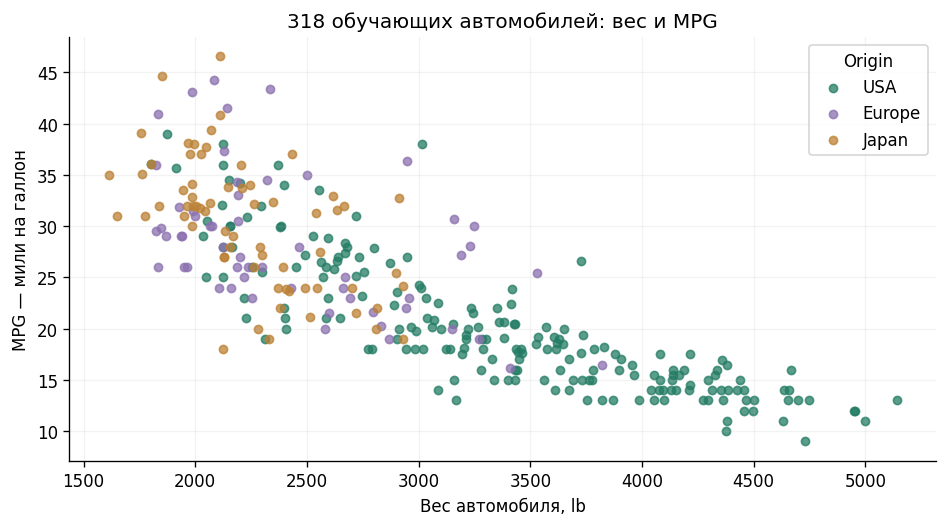

In [1]:
import importlib.util
import subprocess
import sys
packages = {"numpy":"numpy", "pandas":"pandas", "matplotlib":"matplotlib",
            "sklearn":"scikit-learn", "xgboost":"xgboost", "IPython":"ipython"}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import io, json, hashlib, platform, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

SEED = 42
SOURCE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
SOURCE_FILE = Path("auto-mpg.data")
if not SOURCE_FILE.exists():
    SOURCE_FILE.write_bytes(urllib.request.urlopen(SOURCE_URL, timeout=30).read())
raw_bytes = SOURCE_FILE.read_bytes()
SOURCE_SHA256 = hashlib.sha256(raw_bytes).hexdigest()
COLUMNS = ["mpg", "cylinders", "displacement", "horsepower", "weight",
           "acceleration", "model_year", "origin", "car_name"]
df = pd.read_csv(io.BytesIO(raw_bytes), sep=r"\s+", names=COLUMNS, na_values="?")
FEATURES = ["cylinders", "displacement", "horsepower", "weight",
            "acceleration", "model_year", "origin"]
NUMERIC = FEATURES[:-1]
X, y = df[FEATURES], df["mpg"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
assert len(df) == 398 and len(X_train) == 318 and len(X_test) == 80
assert df["horsepower"].isna().sum() == 6
assert set(X_train.index).isdisjoint(X_test.index)
assert y.notna().all()
# car_name — идентификатор: он не передаётся модели.
# Пропуски заполняются внутри Pipeline, отдельно в каждом обучающем fold.
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC),
    ("origin", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["origin"])
], verbose_feature_names_out=False)
def pipeline(estimator):
    return Pipeline([("prepare", clone(preprocessor)), ("model", estimator)])
def metrics(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
            "R2": r2_score(actual, predicted)}
VERSIONS = {"python":platform.python_version(), "numpy":np.__version__,
            "pandas":pd.__version__, "scikit-learn":sklearn.__version__,
            "xgboost":xgboost.__version__}
OUT = Path("results")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120, "font.family":"DejaVu Sans",
                     "axes.spines.top":False, "axes.spines.right":False})
COLORS = ["#247C64", "#8B70AF", "#BC8134", "#3C7DA6"]

print("Версии:", VERSIONS)
print("Источник:", SOURCE_URL)
print("SHA256:", SOURCE_SHA256)
print("Строки / столбцы:", df.shape)
print("Train:", len(X_train), "Test:", len(X_test))
print("Пропуски:", df.isna().sum().to_dict())
display(df.head(10))
df.to_csv("auto_mpg.csv", index=False, float_format="%.10g")
fig, ax = plt.subplots(figsize=(8, 4.5))
for color, origin, label in zip(COLORS, [1,2,3], ["USA", "Europe", "Japan"]):
    mask = X_train["origin"] == origin
    ax.scatter(X_train.loc[mask,"weight"], y_train.loc[mask],
               label=label, color=color, alpha=0.75, s=24)
ax.set(xlabel="Вес автомобиля, lb", ylabel="MPG — мили на галлон",
       title="318 обучающих автомобилей: вес и MPG")
ax.legend(title="Origin")
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(OUT / "01_training_data.png")
plt.show()


## 2. GridSearchCV и кросс-валидация
Для каждой модели проверяем8 наборов параметров на одинаковых пяти folds внутри train. Поочерёдно четыре части обучают, пятая проверяет. Выбираем минимальный средний RMSE. Scikit-learn максимизирует оценку, поэтому используется отрицательный RMSE. Pipeline предотвращает утечку медианы и категорий из валидационной части.

In [2]:
# Один и тот же список пяти folds используется для всех моделей.
cv = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train))
specs = {
    "dt": ("Decision Tree", DecisionTreeRegressor(random_state=SEED),
           {"model__max_depth":[3,5,8,None], "model__min_samples_leaf":[1,4]}),
    "rf": ("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=1),
           {"model__n_estimators":[100,300], "model__max_depth":[None,8],
            "model__min_samples_leaf":[1,2]}),
    "gb": ("Gradient Boosting", GradientBoostingRegressor(random_state=SEED),
           {"model__n_estimators":[100,200], "model__max_depth":[2,3],
            "model__learning_rate":[0.05,0.1]}),
    "xgb": ("XGBoost", XGBRegressor(objective="reg:squarederror", tree_method="hist",
                                   random_state=SEED, n_jobs=1),
            {"model__n_estimators":[100,200], "model__max_depth":[2,3],
             "model__learning_rate":[0.05,0.1]})
}
searches = {}
cv_rows = []
for key, (name, estimator, grid) in specs.items():
    search = GridSearchCV(pipeline(estimator), grid, cv=cv,
                          scoring="neg_root_mean_squared_error", refit=True,
                          n_jobs=1, error_score="raise", return_train_score=True)
    search.fit(X_train, y_train)
    searches[key] = search
    i = search.best_index_
    cv_rows.append({"id":key, "Model":name, "CV RMSE":-search.best_score_,
                    "CV std":search.cv_results_["std_test_score"][i],
                    "Parameters":json.dumps(search.best_params_, ensure_ascii=False)})
    print(name, "CV RMSE =", round(-search.best_score_, 4), search.best_params_)
cv_table = pd.DataFrame(cv_rows)
cv_winner = cv_table.loc[cv_table["CV RMSE"].idxmin(), "id"]
print("Модель, выбранная только по train-CV:", specs[cv_winner][0])
display(cv_table)
cv_table.to_csv(OUT / "cross_validation.csv", index=False)


Decision Tree CV RMSE = 3.6351 {'model__max_depth': 5, 'model__min_samples_leaf': 4}
Random Forest CV RMSE = 2.9649 {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Gradient Boosting CV RMSE = 2.777 {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
XGBoost CV RMSE = 2.7774 {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Модель, выбранная только по train-CV: Gradient Boosting


,id,Model,CV RMSE,CV std,Parameters
0,dt,Decision Tree,3.635115,0.274435,"{""model__max_depth"": 5, ""model__min_samples_le..."
1,rf,Random Forest,2.964857,0.110653,"{""model__max_depth"": null, ""model__min_samples..."
2,gb,Gradient Boosting,2.776956,0.181340,"{""model__learning_rate"": 0.1, ""model__max_dept..."
3,xgb,XGBoost,2.777380,0.127060,"{""model__learning_rate"": 0.05, ""model__max_dep..."


## 3. Проверка на отложенных80 автомобилях
Test не участвовал в выборе параметров. MAE — средняя абсолютная ошибка. RMSE сильнее штрафует крупные промахи. Обе ошибки в MPG, меньше — лучше. R² показывает результат относительно предсказания среднего; значение может быть отрицательным и не является Accuracy. Baseline всегда предсказывает средний MPG обучающей выборки.

In [3]:
# После выбора параметров все модели один раз сравниваются на одинаковом test.
predictions = {}
result_rows = []
for key, search in searches.items():
    fitted = search.best_estimator_
    pred = fitted.predict(X_test)
    predictions[key] = pred
    score = metrics(y_test, pred)
    result_rows.append({"id":key, "Model":specs[key][0],
                        "Train RMSE":metrics(y_train, fitted.predict(X_train))["RMSE"],
                        "CV RMSE":-search.best_score_, **score})
results = pd.DataFrame(result_rows)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_scores = metrics(y_test, baseline_pred)
print("Baseline — всегда среднее train:", baseline_scores)
display(results.round(4))
results.to_csv(OUT / "model_comparison.csv", index=False)
test_winner = results.loc[results["RMSE"].idxmin(), "id"]
print("Минимальный RMSE на этом test:", specs[test_winner][0])
test_table = df.loc[X_test.index].copy()
test_table.insert(0, "csv_row", X_test.index + 2)
for key, pred in predictions.items():
    test_table[f"{key}_predicted_mpg"] = pred
    test_table[f"{key}_absolute_error"] = np.abs(pred - y_test.to_numpy())
test_table.to_csv(OUT / "test_predictions.csv", index=False)
display(test_table.head(10))
# Все 80 отдельных прогнозов доступны в test_predictions.csv.


Baseline — всегда среднее train: {'MAE': 5.955408805031446, 'RMSE': 7.347332711991268, 'R2': -0.00403326341807686}
Минимальный RMSE на этом test: Random Forest


,id,Model,Train RMSE,CV RMSE,MAE,RMSE,R2
0,dt,Decision Tree,2.3716,3.6351,2.0348,2.6976,0.8647
1,rf,Random Forest,1.0797,2.9649,1.5788,2.1574,0.9134
2,gb,Gradient Boosting,1.3271,2.7770,1.7805,2.3612,0.8963
3,xgb,XGBoost,1.4690,2.7774,1.8410,2.5254,0.8814


,csv_row,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,dt_predicted_mpg,dt_absolute_error,rf_predicted_mpg,rf_absolute_error,gb_predicted_mpg,gb_absolute_error,xgb_predicted_mpg,xgb_absolute_error
198,200,33.0,4,91.0,53.0,1795.0,17.4,76,3,honda civic,31.900000,1.100000,31.124333,1.875667,31.420755,1.579245,31.267818,1.732182
396,398,28.0,4,120.0,79.0,2625.0,18.6,82,1,ford ranger,28.369231,0.369231,29.569667,1.569667,29.463704,1.463704,29.849770,1.849770
33,35,19.0,6,232.0,100.0,2634.0,13.0,71,1,amc gremlin,18.750000,0.250000,20.112333,1.112333,21.116600,2.116600,21.376526,2.376526
208,210,13.0,8,318.0,150.0,3940.0,13.2,76,1,plymouth volare premier v8,15.147059,2.147059,14.772000,1.772000,15.714649,2.714649,15.562223,2.562223
93,95,14.0,8,318.0,150.0,4237.0,14.5,73,1,plymouth fury gran sedan,15.147059,1.147059,14.219667,0.219667,13.427781,0.572219,13.141860,0.858140
84,86,27.0,4,97.0,88.0,2100.0,16.5,72,3,toyota corolla 1600 (sw),23.729730,3.270270,25.902000,1.098000,25.249696,1.750304,25.133736,1.866264
373,375,24.0,4,140.0,92.0,2865.0,16.4,82,1,ford fairmont futura,25.672727,1.672727,26.078667,2.078667,27.516824,3.516824,27.050465,3.050465
94,96,13.0,8,440.0,215.0,4735.0,11.0,73,1,chrysler new yorker brougham,12.541667,0.458333,11.856667,1.143333,12.268108,0.731892,12.283324,0.716676
222,224,17.0,8,260.0,110.0,4060.0,19.0,77,1,oldsmobile cutlass supreme,18.500000,1.500000,17.831333,0.831333,19.374741,2.374741,18.994272,1.994272
126,128,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick,16.181818,4.818182,19.471333,1.528667,19.207731,1.792269,19.409048,1.590952


## 4. Сравнение результатов
Победитель по CV — выбор на обучающих данных. Победитель по test — описательный итог на этих80 автомобилях. Они могут различаться. Не перенастраиваем модель после просмотра test. Диагональ на графике «факт — прогноз» соответствует идеальному совпадению.

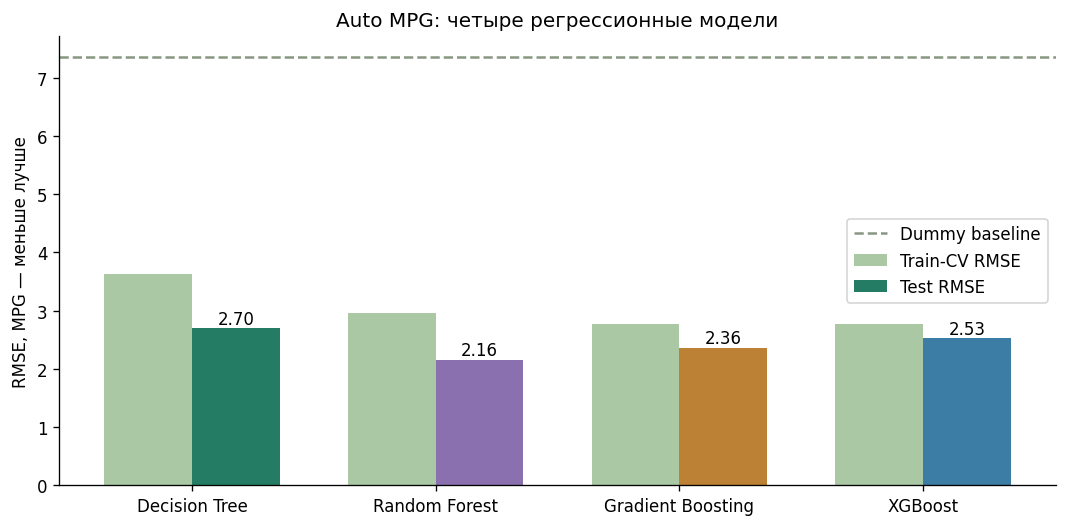

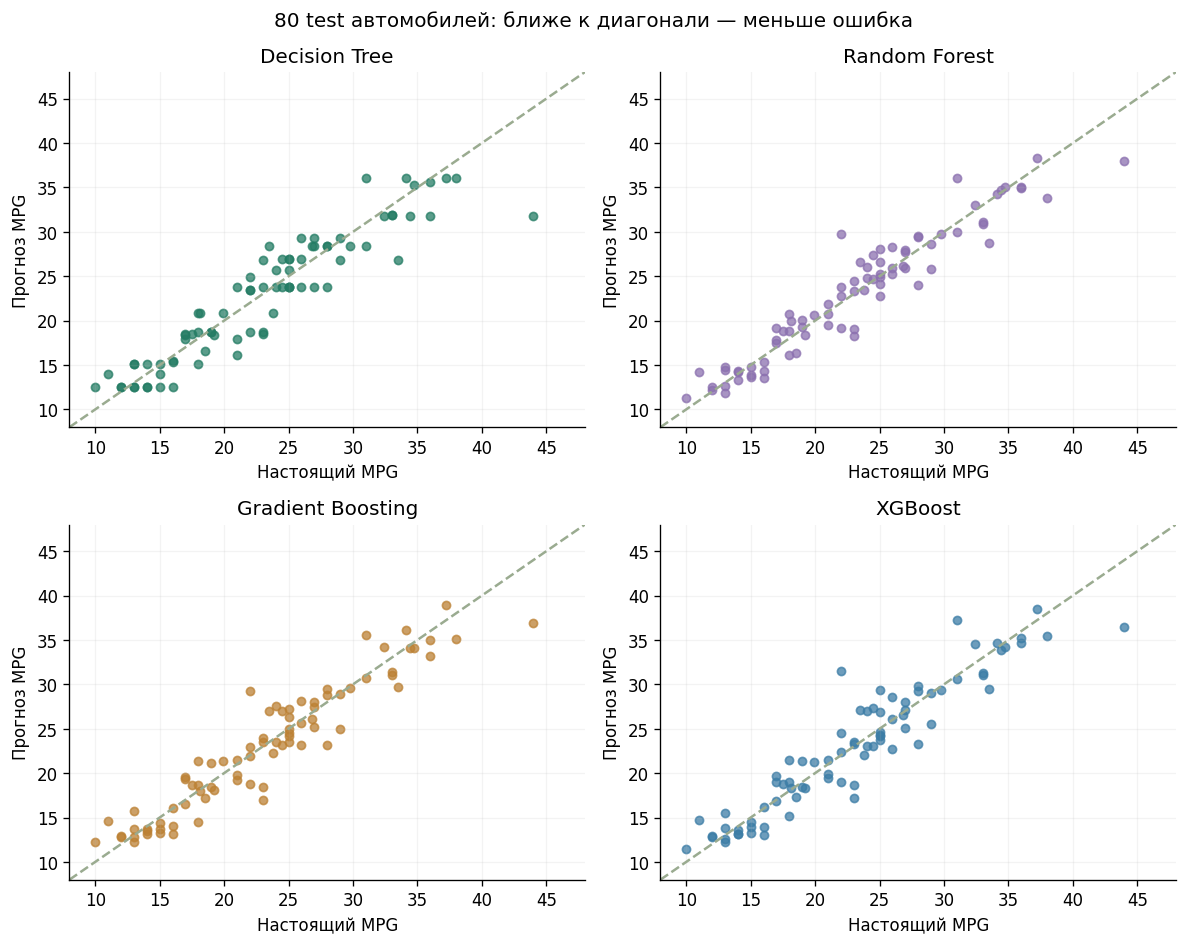

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
xs = np.arange(len(results))
ax.bar(xs-0.18, results["CV RMSE"], width=0.36, label="Train-CV RMSE", color="#A9C8A3")
bars = ax.bar(xs+0.18, results["RMSE"], width=0.36, label="Test RMSE", color=COLORS)
for bar, value in zip(bars, results["RMSE"]):
    ax.text(bar.get_x()+bar.get_width()/2, value+0.08, f"{value:.2f}", ha="center", fontsize=10)
ax.axhline(baseline_scores["RMSE"], ls="--", color="#899782", label="Dummy baseline")
ax.set(xticks=xs, xticklabels=results["Model"], ylabel="RMSE, MPG — меньше лучше",
       title="Auto MPG: четыре регрессионные модели")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "02_rmse_comparison.png")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for (key, pred), ax, color in zip(predictions.items(), axes.flat, COLORS):
    ax.scatter(y_test, pred, color=color, s=24, alpha=0.75)
    ax.plot([8,48],[8,48], "--", color="#9AAB90")
    ax.set(title=specs[key][0], xlabel="Настоящий MPG", ylabel="Прогноз MPG", xlim=(8,48), ylim=(8,48))
    ax.grid(alpha=0.15)
fig.suptitle("80 test автомобилей: ближе к диагонали — меньше ошибка")
fig.tight_layout()
fig.savefig(OUT / "03_actual_vs_predicted.png")
plt.show()


## 5. Как работают дерево и лес
Decision Tree делит строки по порогам признаков и возвращает средний MPG обучающих примеров в листе. Random Forest обучает много деревьев и усредняет их числовые прогнозы. Важность признаков дерева — изменение impurity, а не причинное влияние.

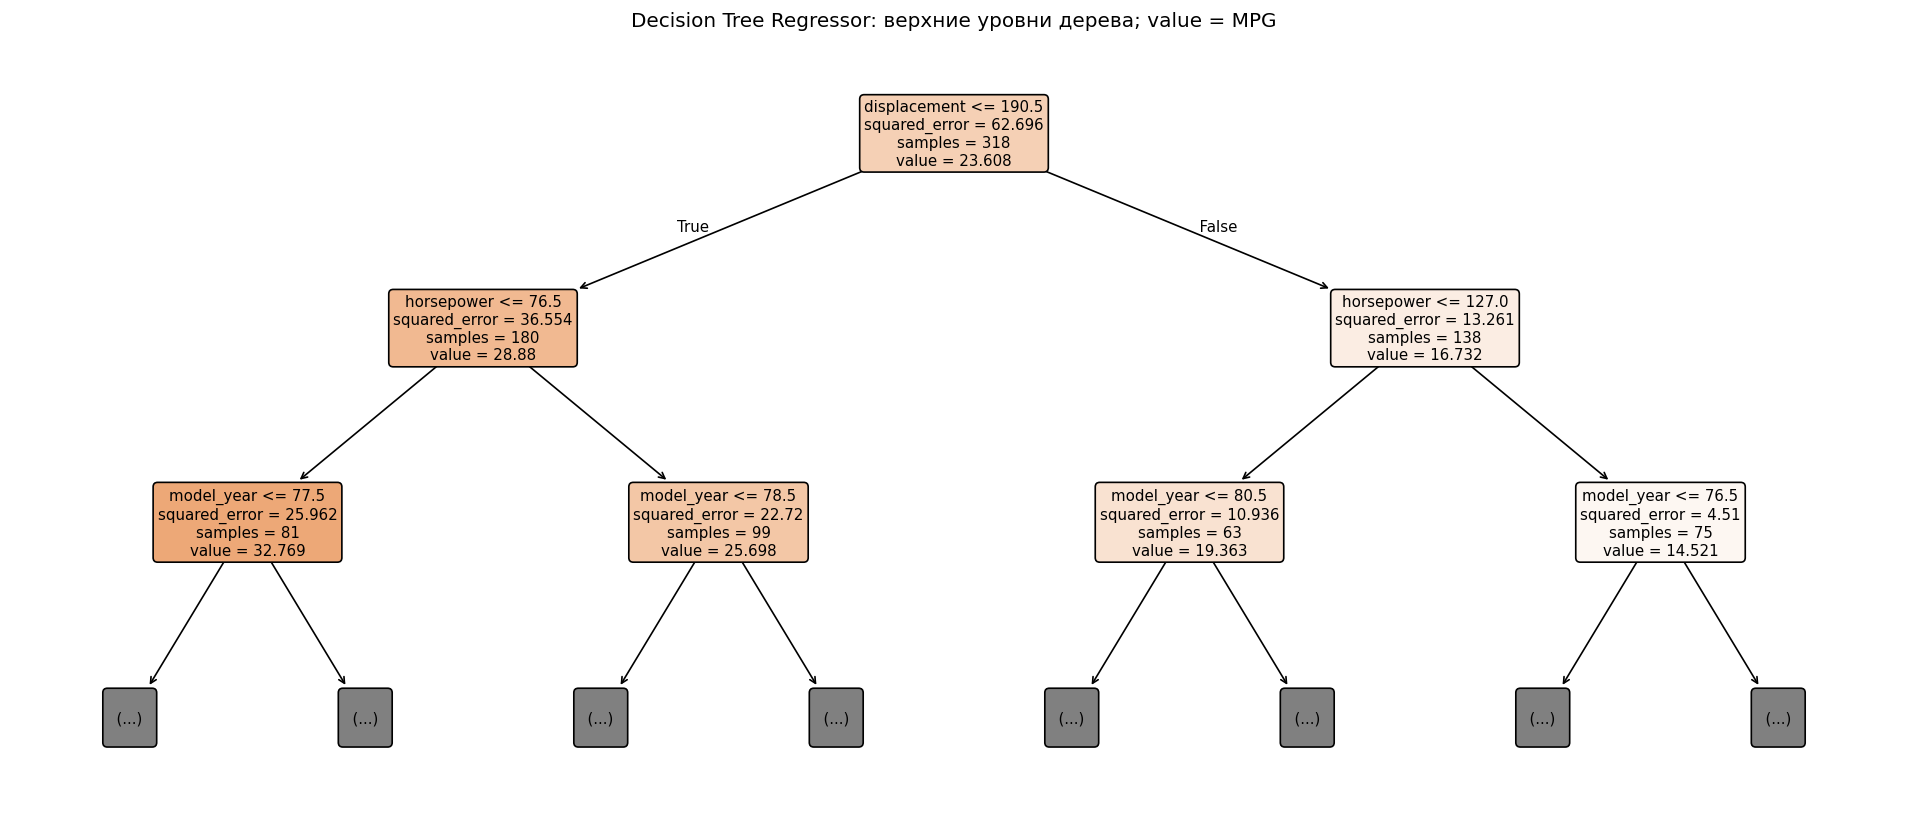

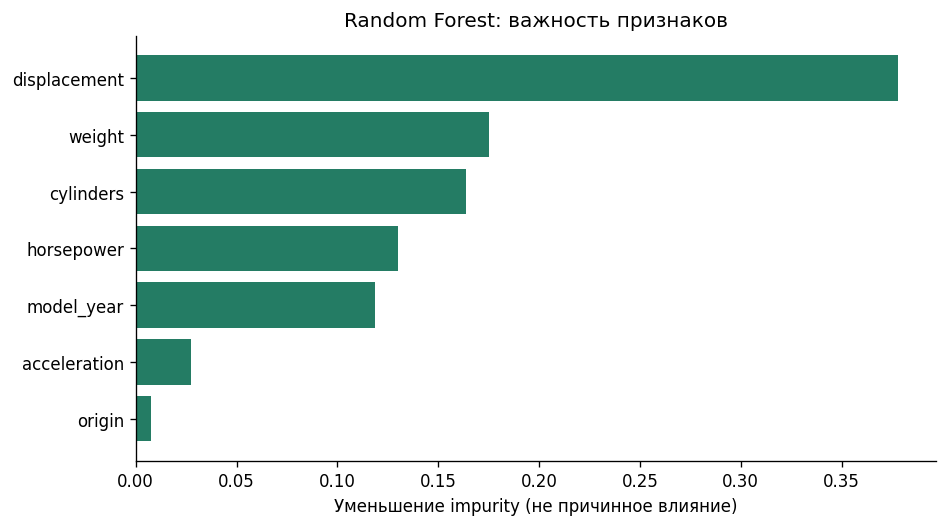

In [5]:
tree_pipeline = searches["dt"].best_estimator_
tree_model = tree_pipeline.named_steps["model"]
transformed_names = tree_pipeline.named_steps["prepare"].get_feature_names_out().tolist()
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree_model, feature_names=transformed_names, max_depth=2,
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree Regressor: верхние уровни дерева; value = MPG")
fig.tight_layout()
fig.savefig(OUT / "04_decision_tree.png")
plt.show()

forest = searches["rf"].best_estimator_.named_steps["model"]
importance = np.r_[forest.feature_importances_[:6], forest.feature_importances_[6:].sum()]
order = np.argsort(importance)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(np.array(FEATURES)[order], importance[order], color="#247C64")
ax.set(title="Random Forest: важность признаков", xlabel="Уменьшение impurity (не причинное влияние)")
fig.tight_layout()
fig.savefig(OUT / "05_feature_importance.png")
plt.show()


## 6. Бустинг и итог
Gradient Boosting постепенно добавляет поправки к прогнозу ансамбля. XGBoost также строит деревья последовательно, используя оптимизированную регуляризованную процедуру. На графике — реальные сохранённые прогнозы выбранных стадий; ошибка одного автомобиля не обязана уменьшаться на каждом шаге.

При показе в классе: «Мы взяли398 автомобилей, предсказали MPG семью признаками, сравнили четыре модели на одних и тех же80 test автомобилях. Лучшую модель выбирали по пятичастной CV внутри train; итоговые ошибки посчитали отдельно».

Новый автомобиль: прогноз MPG
Decision Tree 31.18
Random Forest 33.64
Gradient Boosting 32.57
XGBoost 32.48
По train-CV выбрана Gradient Boosting. Минимальный test RMSE у Random Forest: 2.157 MPG. Это результат конкретного разбиения 318/80, а не гарантия на будущих автомобилях. MPG — мили на галлон: больше MPG означает лучшую топливную экономичность. MAE и RMSE — ошибки в MPG; R² не является процентом правильных ответов.
Out[6]: 316


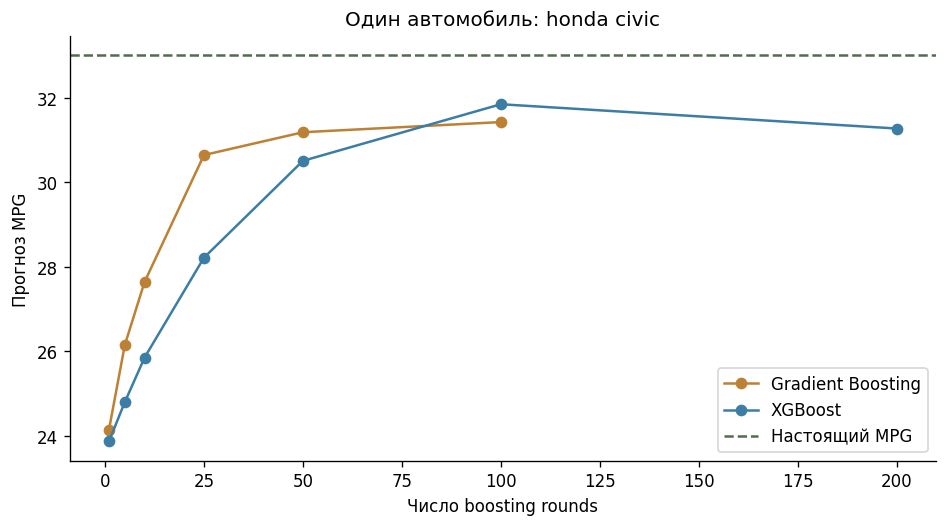

In [6]:
STAGES = {}
STAGE_ROUNDS = {}
for key in ["gb", "xgb"]:
    fitted = searches[key].best_estimator_
    model = fitted.named_steps["model"]
    transformed = fitted.named_steps["prepare"].transform(X_test)
    rounds = [n for n in [1,5,10,25,50,100,200] if n <= model.n_estimators]
    if rounds[-1] != model.n_estimators:
        rounds.append(model.n_estimators)
    STAGE_ROUNDS[key] = rounds
    if key == "gb":
        all_stages = list(model.staged_predict(transformed))
        values = np.column_stack([all_stages[n-1] for n in rounds])
    else:
        values = np.column_stack([model.predict(transformed, iteration_range=(0,n)) for n in rounds])
    assert np.allclose(values[:,-1], predictions[key])
    STAGES[key] = values

sample_index = 0
fig, ax = plt.subplots(figsize=(8, 4.5))
for key, color in [("gb", COLORS[2]), ("xgb", COLORS[3])]:
    ax.plot(STAGE_ROUNDS[key], STAGES[key][sample_index], marker="o", color=color, label=specs[key][0])
ax.axhline(y_test.iloc[sample_index], ls="--", color="#506D4E", label="Настоящий MPG")
ax.set(title=f"Один автомобиль: {df.loc[X_test.index[sample_index], 'car_name']}",
       xlabel="Число boosting rounds", ylabel="Прогноз MPG")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "06_boosting_stages.png")
plt.show()

# Новый пример не использовался при выборе параметров; его реальный MPG неизвестен.
new_car = pd.DataFrame([[4, 120.0, 90.0, 2500.0, 15.0, 80, 3]], columns=FEATURES)
print("Новый автомобиль: прогноз MPG")
for key, search in searches.items():
    print(specs[key][0], round(float(search.best_estimator_.predict(new_car)[0]), 2))

winner_row = results.loc[results["id"] == test_winner].iloc[0]
conclusion = (f"По train-CV выбрана {specs[cv_winner][0]}. "
              f"Минимальный test RMSE у {specs[test_winner][0]}: {winner_row['RMSE']:.3f} MPG. "
              "Это результат конкретного разбиения 318/80, а не гарантия на будущих автомобилях. "
              "MPG — мили на галлон: больше MPG означает лучшую топливную экономичность. "
              "MAE и RMSE — ошибки в MPG; R² не является процентом правильных ответов.")
print(conclusion)
(OUT / "conclusion_ru.txt").write_text(conclusion, encoding="utf-8")


## Источники и воспроизводимость
- UCI Auto MPG: https://doi.org/10.24432/C5859H
- Оригинальный файл UCI: https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data
- Описание полей и единиц для связанного Auto: https://islp.readthedocs.io/en/stable/datasets/Auto.html (там очищенный вариант392 строки; здесь использован UCI398).
- Pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- XGBoost: https://xgboost.readthedocs.io/en/stable/python/python_api.html

Выводы относятся к одному фиксированному разбиению, а не к современной автомобильной популяции. Данные исторические. Версии библиотек, SHA256 оригинала, результаты CV, test и все80 прогнозов сохранены рядом. Данные лицензированы CC BY4.0; перевод в CSV — единственное изменение исходной таблицы.